In [22]:
import random
class State(tuple):
    """
    Stan planszy dziedziczący po tuple
    Plansza to 9-elementowa krotka stringów.
    """
    
    def __new__(cls, board_iterable):
        # __new__ jest wymagane przy dziedziczeniu po typach niemutowalnych (jak tuple)
        return super(State, cls).__new__(cls, board_iterable)
    
    def update(self, move: int, player: str) -> "State":
        """Zwraca nowy stan po wykonaniu ruchu, używając wydajnego wycinania (slicingu)."""
        if not (0 <= move <= 8):
            raise IndexError(f"Niepoprawne pole {move}. Wybierz indeks od 0 do 8.")
        if self[move] != "":
            raise ValueError(f"Pole {move} jest już zajęte przez '{self[move]}'.")

        return State(self[:move] + (player,) + self[move+1:]) # na miejsce o id move wstawiamy znak player

    def __str__(self) -> str:
        v = [val if val else " " for val in self]
        sep = "---+---+---\n"
        row0 = f" 0 | 1 | 2 \n {v[0]} | {v[1]} | {v[2]} \n"
        row1 = f" 3 | 4 | 5 \n {v[3]} | {v[4]} | {v[5]} \n"
        row2 = f" 6 | 7 | 8 \n {v[6]} | {v[7]} | {v[8]} "
        
        return row0 + sep + row1 + sep + row2

# Mapowanie każdego indeksu (0-8) na krotkę wygrywających linii, które przez niego przechodzą.
LINES_FOR_MOVE = {
    0: ((0, 1, 2), (0, 3, 6), (0, 4, 8)),
    1: ((0, 1, 2), (1, 4, 7)),
    2: ((0, 1, 2), (2, 5, 8), (2, 4, 6)),
    3: ((3, 4, 5), (0, 3, 6)),
    4: ((3, 4, 5), (1, 4, 7), (0, 4, 8), (2, 4, 6)),
    5: ((3, 4, 5), (2, 5, 8)),
    6: ((6, 7, 8), (0, 3, 6), (2, 4, 6)),
    7: ((6, 7, 8), (1, 4, 7)),
    8: ((6, 7, 8), (2, 5, 8), (0, 4, 8)),}

WINNING_LINES = (
    (0, 1, 2), (3, 4, 5), (6, 7, 8),
    (0, 3, 6), (1, 4, 7), (2, 5, 8),
    (0, 4, 8), (2, 4, 6) )

def game_result(state: State, empty_char="", last_move: int = None):
    """
    Sprawdza stan gry. Jeżeli last_move jest podany, weryfikuje tylko 
    linie krzyżujące się w miejscu tego ruchu.
    """
    if last_move is not None:
        player = state[last_move]
        
        for a, b, c in LINES_FOR_MOVE[last_move]:
            if state[a] == state[b] == state[c] == player:
                return player
    else:
        for a, b, c in WINNING_LINES:
            if state[a] != empty_char and state[a] == state[b] == state[c]:
                return state[a]
    if empty_char not in state:
        return "draw"
    return None

def game_simulate(
    state: State,
    player_to_move: str,
    win: float = 1.0,
    draw: float = 0.5,
    lose: float = 0.0 ) -> float:
    """
    Doprowadza grę do końca losowymi ruchami i zwraca wynik z perspektywy player_to_move.
    Symulacja typu "brudne i szybkie" - używa mutowalnej listy dla maksymalnej prędkości.
    """
    board = list(state)
    empty_indices = [i for i, val in enumerate(board) if val == ""]
    random.shuffle(empty_indices)

    p = player_to_move
    while empty_indices:
        move = empty_indices.pop()
        
        board[move] = p
        for a, b, c in LINES_FOR_MOVE[move]:
            if board[a] == board[b] == board[c] == p:
    
                return win if p == player_to_move else lose

        p = "O" if p == "X" else "X"

    return draw

In [2]:
import math
class MCTS_Node():
    
    def __init__(self, state: State, player_to_move:str, parent = None, move_taken: int = None, visits = 0, total_score = 0):
        # mimo ze player_to_move da sie uzyskac z podanych argumentow to optymalizacyjnie lepszym podejsciem jest przekazywanie player_to_move
        self.state = state
        self.player_to_move = player_to_move
        self.parent = parent
        self.move_taken = move_taken
        
        self.visits = visits
        self.total_score = total_score

        self.children: dict[int, MCTS_Node] = {}
        
        if game_result(self.state) is not None:
            self.untried_moves = []
        else:
            self.untried_moves = [i for i, v in enumerate(self.state) if v == ""]
    
    def __repr__(self):
        text = ""
        for child in self.children:
            move = child
            score = self.children[child].total_score
            visits = self.children[child].visits 
            text += f'ruch: {move} {self.player_to_move}, symulacyjna liczba wygranych po tym ruchu: {score} / {visits} ({round(score/visits * 100,2)}%)\n'
        return text
        

    def is_fully_expanded(self):
        """
        True - nie mozna wykonac zadnego ruchu
        False - sa ruchy do wykonania
        """
        if not self.untried_moves: # nie mozna wynokac zadnego ruchu
            return True
        else:
            return False
    
    def is_game_over(self):
        return game_result(self.state,last_move= self.move_taken)
    
    def expand(self):
        """tworzy nowy node od rodzica (dzieci) na podstawie dostepnych ruchow"""
        if len(self.untried_moves) == 0:
            return None
        else:
            for move in self.untried_moves:
                state = self.state
                
                new_state = state.update(move, self.player_to_move)
                next_player_to_move = "X" if self.player_to_move == "O" else "O"
                
                self.children[move] = MCTS_Node(state=new_state,
                                                player_to_move=next_player_to_move,
                                                parent=self,
                                                move_taken=move )
            self.untried_moves = [] # aby przekazac ze po rozbudowie nie ma juz dostepnych ruchow
            return self.children
    
    def UCB(self, c=1.41):
        """Wybiera najlepsze dziecko węzła na podstawie kryterium UCB."""
        parent_visits = self.visits

        best_ucb = -float("inf")
        best_child = None

        for child in self.children.values():
            if child.visits == 0:
                return child

            q = child.total_score / child.visits
            exploration = c * math.sqrt((2 * math.log(parent_visits)) / child.visits)

            ucb = q + exploration

            if ucb > best_ucb:
                best_ucb = ucb
                best_child = child

        return best_child 

    def backpropagate(self, result:float):
        current = self
        current_result = result # wynik sumulacji
        while current is not None:
            current.visits += 1
            current.total_score += current_result

            current_result = 1- current_result
            current = current.parent
                           

In [3]:
def mcts_search(state: State, player: str, iterations: int = 1000, return_root: bool = False):

    root = MCTS_Node(state=state, player_to_move=player)
    
    if not root.untried_moves or root.is_game_over() is not None:
        return None
    if len(root.untried_moves) == 1:
        return (root.untried_moves[0], root) if return_root else root.untried_moves[0]
    
    for _ in range(iterations):
        node = root
        
        # 1. Selekcja (są dzieci, idziemy głębiej dopóki gra trwa)
        while node.is_fully_expanded() and (node.is_game_over() is None):
            node = node.UCB()
        
        # 2. Ekspansja (nie ma dzieci, tworzymy je i wybieramy jedno)
        if node.is_game_over() is None and not node.is_fully_expanded():        
            node.expand()
            node = node.UCB()
        
        terminal_state = node.is_game_over()
        
        if terminal_state is not None:
            if terminal_state == "draw":
                sim_result = 0.5
            else:
                sim_result = 1.0
        else:
            sim_result = 1.0 - game_simulate(node.state, player_to_move=node.player_to_move)
        
        node.backpropagate(sim_result)
        
    best_move = max(root.children.items(), key=lambda item: item[1].visits)[0]
    if return_root:
        return best_move, root
    else:
        return best_move

In [4]:
def play_game(algorytm_iter: int = 10):
    state = State(*["" for _ in range(9)]) # inicjacja pustej planszy
    computer_mark = 'O'
    player_mark = 'X'
    state = state.update(mcts_search(state, player='O', iterations=algorytm_iter),computer_mark)        

    while game_result is not None:
        print('-'*30)
        player_move = int(input(f'twoj ruch (wpisz numer ruchu) {print(state)}'))
        state = state.update(player_move, player_mark)
        
        if game_result(state) != None:
            return f'wynik {game_result(state)}'

        computer_move = mcts_search(state, computer_mark)
        state = state.update(computer_move, computer_mark)
        
        if game_result(state) != None:
            return f'wynik {game_result(state)}'


In [5]:
from typing import Callable

def artificial_game_simulation(
    player1_fn: Callable[[State, str], int],
    player2_fn: Callable[[State, str], int],
    start: int = 1 ) -> float:
    state = State(("" for _ in range(9)))
    
    # Ustalenie, kto gra jakim symbolem
    p1_mark = 'O' if start == 1 else 'X'
    # 'O' zawsze rozpoczyna partię
    current_mark = 'O'

    while game_result(state) is None:
        if current_mark == p1_mark:
            move = player1_fn(state, current_mark)
        else:
            move = player2_fn(state, current_mark)

        state = state.update(move, current_mark)
        current_mark = 'X' if current_mark == 'O' else 'O'

    result = game_result(state)

    if result == p1_mark:
        return 1.0
    elif result == "draw":
        return 0.5 
    else:
        return 0.0

In [6]:
import tqdm
import cProfile
import pstats

num_sym = 100
m = 1_000
result = []

profiler = cProfile.Profile()
profiler.enable()

for n in tqdm.trange(1, 1_000, 50):
    result.append(sum([artificial_game_simulation(
    player1_fn=lambda state, mark: mcts_search(state, mark,m),
    player2_fn=lambda state, mark: mcts_search(state, mark, n))  for _ in range(1, 101)]))

profiler.disable()

stats = pstats.Stats(profiler)
stats.sort_stats(pstats.SortKey.CUMULATIVE)
stats.print_stats(20)

100%|██████████| 20/20 [02:54<00:00,  8.73s/it]

         782371561 function calls (782371309 primitive calls) in 174.560 seconds

   Ordered by: cumulative time
   List reduced from 507 to 20 due to restriction <20>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      3/2    0.000    0.000  174.556   87.278 /Users/ignacyboczula/Desktop/coding_vs/model_kolko_krzyrzyk/.venv/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3786(run_code)
     11/2    0.000    0.000  174.556   87.278 {built-in method builtins.exec}
     2000    0.012    0.000  173.856    0.087 /var/folders/02/58ywv9f514l59fv2ts8pdcn80000gn/T/ipykernel_37621/3926336495.py:3(artificial_game_simulation)
    16086   17.438    0.001  173.430    0.011 /var/folders/02/58ywv9f514l59fv2ts8pdcn80000gn/T/ipykernel_37621/3002343376.py:1(mcts_search)
     9043    0.003    0.000  126.089    0.014 /var/folders/02/58ywv9f514l59fv2ts8pdcn80000gn/T/ipykernel_37621/1240580360.py:14(<lambda>)
 42067248   41.702    0.000   60.710    0.000 /var/folders/

In [54]:
import pstats
import pandas as pd

stats = pstats.Stats(profiler)
total_time = stats.total_tt 


IGNORED_FUNCS = {"<lambda>", "<module>", "<listcomp>", "<genexpr>", "exec", "eval", "run_code"}
IGNORED_PATHS = ("site-packages/IPython", "site-packages/ipykernel", "site-packages/tqdm", "asyncio")

rows = []
for (filename, line, func_name), (cc, nc, tt, ct, callers) in stats.stats.items():

    if func_name in IGNORED_FUNCS:
        continue
    if any(ignored in filename for ignored in IGNORED_PATHS):
        continue


    if (tt / total_time) < 0.005 and (ct / total_time) < 0.02:
        continue


    source = "Twój kod" if "ipykernel_" in filename else "Biblioteka"

    rows.append({
        "Funkcja": func_name,
        "Źródło": source,
        "Wywołania": nc,
        "Czas własny [s]": tt,
        "Udział własny [%]": (tt / total_time) * 100,
        "Czas łączny [s]": ct,
        "Czas / wyw. [µs]": (tt / nc) * 1e6 if nc > 0 else 0.0,
    })

df_prof = (
    pd.DataFrame(rows)
    .sort_values(by="Czas własny [s]", ascending=False)
    .reset_index(drop=True)
)

print(f"Całkowity czas wykonania: {total_time:.2f} s\n")

print(df_prof.to_string(
    index=False,
    formatters={
        "Wywołania": "{:,}".format,
        "Czas własny [s]": "{:.3f}".format,
        "Udział własny [%]": "{:.1f}%".format,
        "Czas łączny [s]": "{:.3f}".format,
        "Czas / wyw. [µs]": "{:.2f}".format,
    }
))


Całkowity czas wykonania: 174.56 s

                                                Funkcja     Źródło   Wywołania Czas własny [s] Udział własny [%] Czas łączny [s] Czas / wyw. [µs]
                                                    UCB   Twój kod  42,067,248          41.702             23.9%          60.710             0.99
                                            game_result   Twój kod  87,733,014          25.708             14.7%          25.708             0.29
                                               __init__   Twój kod  22,173,689          19.751             11.3%          31.594             0.89
                                            mcts_search   Twój kod      16,086          17.438             10.0%         173.430          1084.04
                                                 expand   Twój kod   5,136,462           9.717              5.6%          53.502             1.89
                             <built-in method math.log> Biblioteka 158,290,590          

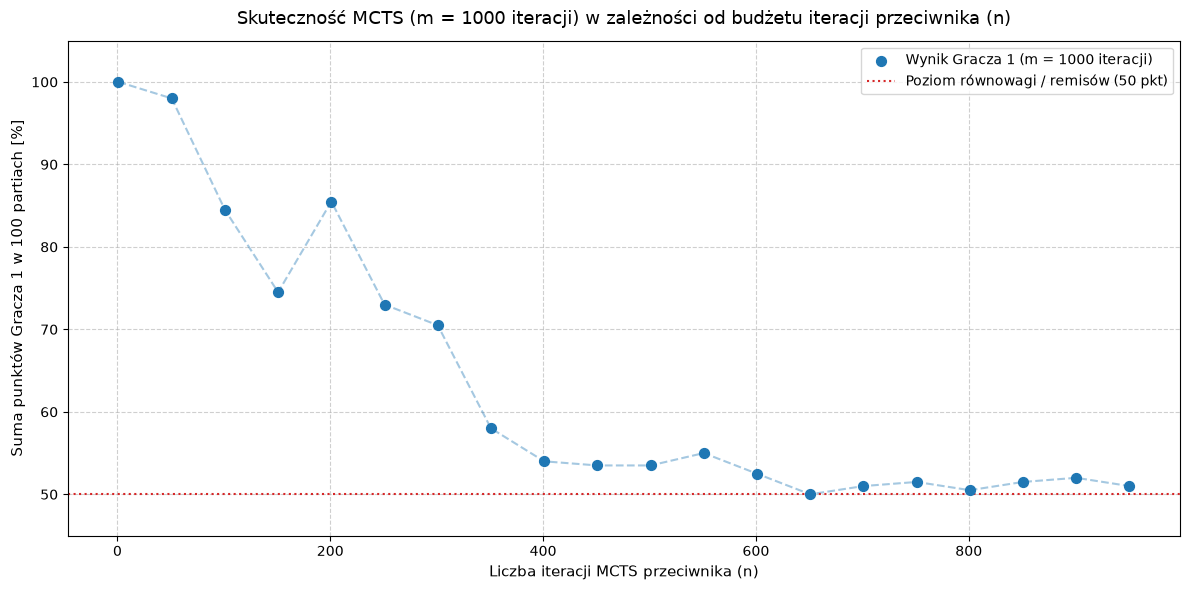

In [50]:
import matplotlib.pyplot as plt
import numpy as np

iterations_p2 = np.arange(1, 1000, 50)

plt.figure(figsize=(12, 6))

plt.plot(iterations_p2, result, linestyle="--", alpha=0.4, color="tab:blue")
plt.scatter(iterations_p2, result, color="tab:blue", s=50, zorder=3, label="Wynik Gracza 1 (m = 1000 iteracji)")

plt.axhline(50, color="tab:red", linestyle=":", linewidth=1.5, label="Poziom równowagi / remisów (50 pkt)")
plt.title("Skuteczność MCTS (m = 1000 iteracji) w zależności od budżetu iteracji przeciwnika (n)", fontsize=13, pad=12)
plt.xlabel("Liczba iteracji MCTS przeciwnika (n)", fontsize=11)
plt.ylabel("Suma punktów Gracza 1 w 100 partiach [%]", fontsize=11)

# Zakres osi, siatka i legenda
plt.ylim(45, 105)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [40]:
# algorytm minimax ocenia kazdy mozliwy ruch i znajduje wygrywajacy w najmniejszej liczba ruchow
def minimax(state: State, d: int, maximizer: bool, mark_maximizer: str, last_move: int = None, policy: dict = None, build_policy: bool = False):
    result = game_result(state, last_move=last_move)
    
    if result is not None:
        if result == mark_maximizer:
            return 10 - d
        elif result == "draw":
            return 0
        else:
            return -(10 - d)

    opponent = "O" if mark_maximizer == "X" else "X"
    current_player = mark_maximizer if maximizer else opponent
    
    cache_key = (tuple(state), current_player, mark_maximizer)
    if build_policy and policy is not None and cache_key in policy:
        return policy[cache_key][0]
    
    possible_moves = [i for i, v in enumerate(state) if v == ""]
    best_move = None
    if maximizer:
        max_val = -math.inf
        for move in possible_moves:
            new_state = state.update(move, current_player)
            val = minimax(new_state, d + 1, False, mark_maximizer, last_move=move, policy= policy, build_policy=build_policy)
            if val > max_val:
                max_val = val
                best_move = move
        
        if build_policy and policy is not None:
            policy[cache_key] = (max_val, best_move)
        return max_val
    else:
        min_val = math.inf
        for move in possible_moves:
            new_state = state.update(move, current_player)
            val = minimax(new_state, d + 1, True, mark_maximizer, last_move=move, policy= policy, build_policy=build_policy)
            if val < min_val:
                min_val = val
                best_move = move
        
        if build_policy and policy is not None:
            policy[cache_key] = (min_val, best_move)
        return min_val


def find_move_minimax(state: State, player_to_move: str, policy: dict = None, build_policy: bool = False) -> int:
    # Tryb odczytu: jeśli mamy gotowy słownik i nie jesteśmy w trybie budowania
    if not build_policy and policy is not None:
        for mark in ("X", "O"):
            if (tuple(state), player_to_move, mark) in policy:
                return policy[(tuple(state), player_to_move, mark)][1]
    
    possible_moves = [i for i, v in enumerate(state) if v == ""]
    best_move = None
    best_score = -math.inf
    
    for move in possible_moves:
        new_state = state.update(move, player_to_move)
        
        val = minimax(new_state, d=1, maximizer=False, mark_maximizer=player_to_move, last_move=move, policy=policy, build_policy=build_policy)
        
        if val > best_score:
            best_score = val
            best_move = move
    if build_policy and policy is not None:
        policy[(tuple(state), player_to_move, player_to_move)] = (best_score, best_move)     
    
    return best_move

In [41]:
# slownik z najlepszym ruchem dla kazdego mozliwego stanu: key (state, current_player), value: move
policy_dict = {}
empty_state = State(("",) * 9)


find_move_minimax(empty_state, player_to_move="X", policy=policy_dict, build_policy=True)
find_move_minimax(empty_state, player_to_move="O", policy=policy_dict, build_policy=True)
len(policy_dict)

9040

In [47]:
import numpy as np
import pandas as pd
from tqdm import tqdm

# Geometrycznie dobrane poziomy iteracji (zagęszczone na początku)
iteration_levels = np.unique(
    np.geomspace(1, 2000, num=50).astype(int)
).tolist()

GAMES_PER_ROLE = 150  # 50 gier jako 'O' (start) + 50 jako 'X' (drugi) = 100 gier na poziom

# Agent Minimax korzystający bezpośrednio z gotowego słownika w czasie O(1)
minimax_agent = lambda state, mark: find_move_minimax(state, mark, policy=policy_dict)

results = []

print(f"Testowane poziomy iteracji: {iteration_levels}")
print(f"Łącznie gier: {len(iteration_levels) * GAMES_PER_ROLE * 2}\n")

# Pętla główna z paskiem postępu tqdm
for iters in tqdm(iteration_levels, desc="Ewaluacja MCTS vs Minimax"):
    mcts_agent = lambda state, mark: mcts_search(state, mark, iters)

    mcts_wins = 0
    draws = 0
    minimax_wins = 0
    total_score = 0.0

    # 1. MCTS gra jako Gracz 1 ('O' - zaczyna)
    for _ in range(GAMES_PER_ROLE):
        score = artificial_game_simulation(
            player1_fn=mcts_agent,
            player2_fn=minimax_agent,
            start=1
        )
        total_score += score
        if score == 1.0:
            mcts_wins += 1
        elif score == 0.5:
            draws += 1
        else:
            minimax_wins += 1

    # 2. Minimax gra jako Gracz 1 ('O' - zaczyna), MCTS jako Gracz 2 ('X')
    for _ in range(GAMES_PER_ROLE):
        score_p1 = artificial_game_simulation(
            player1_fn=minimax_agent,
            player2_fn=mcts_agent,
            start=1
        )
        # artificial_game_simulation zwraca wynik z perspektywy Gracza 1 (tu: Minimax)
        if score_p1 == 1.0:
            minimax_wins += 1
        elif score_p1 == 0.5:
            draws += 1
            total_score += 0.5
        else:
            mcts_wins += 1
            total_score += 1.0

    total_games = GAMES_PER_ROLE * 2
    avg_score = total_score / total_games
    draw_rate = draws / total_games

    results.append({
        "mcts_iterations": iters,
        "mcts_wins": mcts_wins,
        "draws": draws,
        "minimax_wins": minimax_wins,
        "mcts_loss_rate": minimax_wins / total_games,
        "draw_rate": draw_rate,
        "mcts_avg_score": avg_score
    })

df_results = pd.DataFrame(results)
print("\nPodsumowanie wyników:")
print(df_results.to_string(index=False))

Testowane poziomy iteracji: [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 13, 16, 19, 22, 25, 30, 35, 41, 48, 56, 65, 76, 89, 104, 122, 143, 167, 195, 227, 266, 310, 363, 423, 495, 578, 675, 788, 920, 1075, 1255, 1466, 1712, 2000]
Łącznie gier: 12900



Ewaluacja MCTS vs Minimax: 100%|██████████| 43/43 [02:07<00:00,  2.96s/it]


Podsumowanie wyników:
 mcts_iterations  mcts_wins  draws  minimax_wins  mcts_loss_rate  draw_rate  mcts_avg_score
               1          0      0           300        1.000000   0.000000        0.000000
               2          0      0           300        1.000000   0.000000        0.000000
               3          0      0           300        1.000000   0.000000        0.000000
               4          0      0           300        1.000000   0.000000        0.000000
               5          0      0           300        1.000000   0.000000        0.000000
               6          0     20           280        0.933333   0.066667        0.033333
               7          0      9           291        0.970000   0.030000        0.015000
               8          0      2           298        0.993333   0.006667        0.003333
              10          0     28           272        0.906667   0.093333        0.046667
              11          0     86           214        0

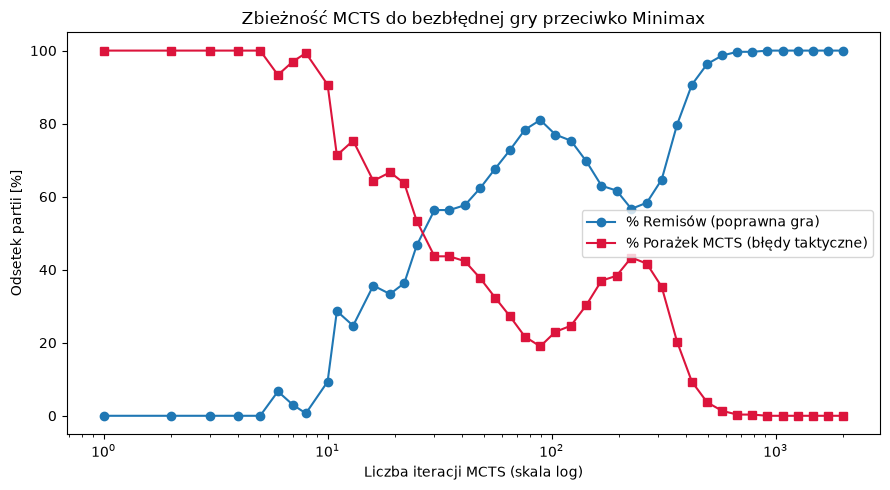

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.plot(df_results["mcts_iterations"], df_results["draw_rate"] * 100, marker='o', label="% Remisów (poprawna gra)")
plt.plot(df_results["mcts_iterations"], df_results["mcts_loss_rate"] * 100, marker='s', color='crimson', label="% Porażek MCTS (błędy taktyczne)")

plt.xscale("log")
plt.xlabel("Liczba iteracji MCTS (skala log)")
plt.ylabel("Odsetek partii [%]")
plt.title("Zbieżność MCTS do bezbłędnej gry przeciwko Minimax")

plt.legend()
plt.tight_layout()
plt.show()